# B1: rebuilt CCD (tree-ring) maps -- validation

Maps rebuilt from all 000-063 Gaia stars (sigma < 10 mas, with g - i, not bright/saturated), after the current DCR model,
by `py_files/ringmap_build.py` on a compute node (`sample validate build`). Validation: maps from 80% of the bricks,
applied to the other 20%; robust per-axis scatter of the held-out offsets (mas) with no map, the 2024 maps, and new maps
with 16 / 32 / 64-px bins. Lower is better; a map that adds scatter (above "none") hurts.

In [1]:
import os, sys, json
import numpy as np
import matplotlib.pyplot as plt
sys.path.append(os.path.abspath('..'))
from py_files import plot_style as ps
from py_files.ringmap_build import COMBINED_DIR   # the v1 combined files the adopted maps were built from
ps.apply()
V = json.load(open(os.path.join(COMBINED_DIR, 'ringmap-validation.json')))
BANDS = 'griz'
print(f"train {V['n_train']:,} epochs, test {V['n_test']:,}")
print(f"{'version':12s}" + ''.join(f'{b:>8s}' for b in BANDS))
for name, d in V['scatter_mas'].items():
    print(f'{name:12s}' + ''.join(f'{d[b]:8.2f}' for b in BANDS))
print('removed vs none (quadrature, mas; negative = adds scatter):')
for name, d in V['scatter_mas'].items():
    if name == 'none': continue
    n = V['scatter_mas']['none']
    print(f'{name:12s}' + ''.join(f'{np.sign(n[b] - d[b]) * np.sqrt(abs(n[b]**2 - d[b]**2)):8.2f}' for b in BANDS))

train 236,478,083 epochs, test 57,488,319
version            g       r       i       z
none           14.60   13.11   12.37   11.33
maps 2024      17.14   12.31   11.27   10.82
new 16 px      12.41   10.82    9.87    9.56
new 32 px      12.67   11.17   10.20    9.73
new 64 px      13.22   11.77   10.78   10.06
removed vs none (quadrature, mas; negative = adds scatter):
maps 2024      -8.99    4.51    5.10    3.34
new 16 px       7.69    7.40    7.46    6.07
new 32 px       7.25    6.85    7.00    5.80
new 64 px       6.19    5.77    6.08    5.21


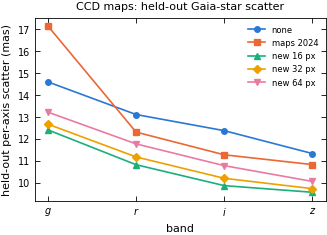

In [2]:
# Held-out scatter per band and map version
fig, ax = plt.subplots(figsize=(ps.COLUMN, 2.4), constrained_layout=True)
names = list(V['scatter_mas'])
for k, name in enumerate(names):
    ax.plot(range(4), [V['scatter_mas'][name][b] for b in BANDS], marker=ps.MARKERS[k], color=ps.SERIES[k], label=name)
ax.set_xticks(range(4), [f'${b}$' for b in BANDS]); ax.set_xlabel('band')
ax.set_ylabel('held-out per-axis scatter (mas)'); ax.legend(fontsize=6)
ax.set_title('CCD maps: held-out Gaia-star scatter')
plt.savefig('plots/ringmap_validation.pdf')

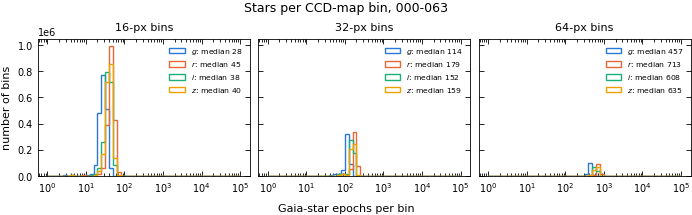

In [3]:
# Epochs per bin (all bricks) for each bin size
fig, axes = plt.subplots(1, 3, figsize=(ps.PAGE, 2.2), sharey=True, constrained_layout=True)
for ax, b in zip(axes, (16, 32, 64)):
    n = np.load(os.path.join(COMBINED_DIR, f'ringmaps-dr10-b{b}-counts.npz'))['counts']
    for j, band in enumerate(BANDS):
        v = n[j::4].ravel(); v = v[v > 0]
        ax.hist(v, bins=np.logspace(0, 5, 51), histtype='step', color=ps.SERIES[j], label=f'${band}$: median {np.median(v):.0f}')
    ax.set_xscale('log'); ax.set_title(f'{b}-px bins'); ax.legend(fontsize=5.5)
axes[0].set_ylabel('number of bins'); fig.supxlabel('Gaia-star epochs per bin', fontsize=8)
fig.suptitle('Stars per CCD-map bin, 000-063')
plt.savefig('plots/ringmap_counts.pdf')